In [5]:
%pip install numpy matplotlib seaborn pylatexenc sympy "qiskit>=2.0" "qiskit-aer>=0.17" --quiet

Note: you may need to restart the kernel to use updated packages.


In [6]:
import math
import random
import numpy as np
from scipy.optimize import minimize
import matplotlib.pyplot as plt
from IPython.display import display

from qiskit import QuantumCircuit, transpile, QuantumRegister, ClassicalRegister
from qiskit.quantum_info import Statevector, state_fidelity
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_distribution, plot_state_city, plot_state_qsphere

In [7]:
# num_of_elements = 2
num_of_features = 4
# dataset = [
#     [random.randint(0, 255) for _ in range(num_of_features)] for _ in range(num_of_elements)
# ]

In [8]:
hex_images = [0x0, 0x1, 0x2, 0x3, 0x4, 0x5, 0x6, 0x7, 0x8, 0x9, 0xA, 0xB, 0xC, 0xD, 0xE, 0xF]
dataset = [[(h >> j) & 1 for j in range(num_of_features)] for h in hex_images]

In [9]:
query_index = random.randint(0, len(dataset) - 1)
query = dataset[query_index]

In [10]:
dataset

[[0, 0, 0, 0],
 [1, 0, 0, 0],
 [0, 1, 0, 0],
 [1, 1, 0, 0],
 [0, 0, 1, 0],
 [1, 0, 1, 0],
 [0, 1, 1, 0],
 [1, 1, 1, 0],
 [0, 0, 0, 1],
 [1, 0, 0, 1],
 [0, 1, 0, 1],
 [1, 1, 0, 1],
 [0, 0, 1, 1],
 [1, 0, 1, 1],
 [0, 1, 1, 1],
 [1, 1, 1, 1]]

In [11]:
query_index

1

In [12]:
query

[1, 0, 0, 0]

### **<u>PART 1: APPROXIMATE AMPLITUDE ENCODING USING PARAMETERIZED QUANTUM CIRCUIT</u>**

Step 1. Calculate number of required qubits 

Step 2. Prepare target state (normzalition, padding) -> O(N_I * N_D)

Step 3. Prepare gaussian kernel and hadamard for the given dataset shape -> O((2^ceil(log(N_I))) * (2^ceil(log(N_D)))) ≈ O(N_I * N_D)

Step 4. Randomly initialize a list of theta for the Ry layers of the parameterized quantum circuit -> O(depth * log() + log())

Step 5. Define the objective function which is to minimize the loss (MMD)

Step 6. Prepare parameterized quantum circuit using the Ry and CNOT gates in a single layer for a given number of layers/depth of the circuit

Step 7. Calculate the final state from the circuit

Step 8. Calculate loss (MMD between the measured state and the target state)

Step 9. Calculate gradients (parameter shift rule) and update the parameters using adam optimizer

Step 10. Repeat until loss minimized or max epochs reached


In [13]:
import numpy as np
import math
import matplotlib.pyplot as plt
from qiskit import QuantumCircuit
from qiskit.quantum_info import Statevector, state_fidelity

class ApproximateAmplitudeEncoder:
    """
    Corrected encoder handling little-endian bit-ordering for Qiskit compatibility.
    """

    def __init__(self):
        self.rng = np.random.default_rng(42)

    # ----------- ENCODING SCHEME -----------

    def prepare_neqr_dataset_target(self, dataset):
        dataset = np.array(dataset, dtype=float, copy=True)
        self.N_I, self.N_D = dataset.shape
        self.n_index_q = math.ceil(math.log2(self.N_I)) if self.N_I > 1 else 1
        self.n_data_q = math.ceil(math.log2(self.N_D)) if self.N_D > 1 else 1

        self.min_value = 0
        self.max_value = int(np.max(dataset))
        self.n_value_q = max(1, math.ceil(math.log2(self.max_value + 1)))

        total_qubits = self.n_index_q + self.n_data_q + self.n_value_q
        total_num_states = 2**total_qubits

        print(f"\nNum of data elements (N_I): {self.N_I}")
        print(f"Num of features (N_D): {self.N_D}")
        print(f"Number of index qubits (n_index_q): {self.n_index_q}")
        print(f"Number of data qubits (n_data_q): {self.n_data_q}")
        print(f"Number of value qubits (n_value_q): {self.n_value_q}")
        print(f"Total number of qubits (total_qubits): {total_qubits}")
        print("Total number of states: ", total_num_states)

        target = np.zeros(total_num_states, dtype=complex)  
        amplitude = 1 / np.sqrt(self.N_I * self.N_D)
        print("\nAmplitude = ", amplitude)

        for i in range(self.N_I):
            for j in range(self.N_D):
                value = int(dataset[i, j])

                # Qiskit Little-Endian Layout:
                # Qubits order from right to left: |value> |feature> |index>
                # index = i (lowest bits) + (j shifted by n_index_q) + (value shifted by n_index_q + n_data_q)
                index = (
                    i 
                    + (j << self.n_index_q)  
                    + (value << (self.n_index_q + self.n_data_q)) 
                )

                target[index] = amplitude

        return Statevector(target)

    def prepare_neqr_query_target(self, query):
        query = np.array(query, dtype=int, copy=True)
        
        N_D = len(query)
        n_data_q = math.ceil(math.log2(N_D)) if N_D > 1 else 1

        total_qubits = self.n_value_q + n_data_q
        total_num_states = 2**total_qubits

        print(f"\nNumber of feature qubits (n_data_q): {n_data_q}")
        print(f"Number of value qubits (n_value_q): {self.n_value_q}")
        print(f"Total number of qubits (total_qubits): {total_qubits}")
        print(f"Total number of states (total_num_states): {total_num_states}")

        target = np.zeros(total_num_states, dtype=complex)
        amplitude = 1 / np.sqrt(N_D)

        for j, value in enumerate(query):
            # Little-endian order: |value> |feature>
            index = j + (int(value) << n_data_q)
            target[index] = amplitude

        return Statevector(target)

    # ----------- KERNEL & LOSS FUNCTIONS -----------

    def gaussian_kernel_matrix(self, N):
        """
        Computes an N x N Gaussian kernel matrix safely.
        k(i,j) = exp(-64 * (i-j)^2)
        """
        if N > 4096:
            raise ValueError(f"State space size {N} is too large for dense MMD kernel matrix computation.")
        indices = np.arange(N, dtype=float)
        differences = indices[:, None] - indices[None, :]
        return np.exp(-64 * differences**2)

    def mmd_loss(self, P, Q, kernel):
        """
        Squared MMD between two discrete probability distributions:
        MMD^2(P,Q) = P.T @ K @ P + Q.T @ K @ Q - 2 * P.T @ K @ Q
        """
        P = np.asarray(P, dtype=float).ravel()
        Q = np.asarray(Q, dtype=float).ravel()

        if P.shape != Q.shape:
            raise ValueError("P and Q must have the same length.")

        loss = ((P @ kernel @ P) + (Q @ kernel @ Q) - (2 * P @ kernel @ Q))
        return max(float(loss), 0.0)

    def walsh_hadamard_transform(self, state):
        state = np.asarray(state, dtype=complex).copy()
        N_D = len(state)

        if N_D == 0 or (N_D & (N_D - 1)) != 0:
            raise ValueError("State-vector length must be a power of 2.")

        step = 1
        while step < N_D:
            for start in range(0, N_D, 2 * step):
                a = state[start:start + step].copy()
                b = state[start + step:start + 2 * step].copy()

                state[start:start + step] = a + b
                state[start + step:start + 2 * step] = a - b

            step *= 2

        return state / np.sqrt(N_D)

    def cost_function(self, parameters, target_amplitudes, kernel, depth, n_qubits):
        qc = self.pqc(parameters, depth, n_qubits)
        state = Statevector.from_instruction(qc)
        amplitudes = np.real_if_close(state.data).real

        probability_1 = np.abs(amplitudes) ** 2
        target_probability_1 = np.abs(target_amplitudes) ** 2
        L1 = self.mmd_loss(probability_1, target_probability_1, kernel)

        transformed_amplitudes = self.walsh_hadamard_transform(amplitudes)
        target_transformed_amplitudes = self.walsh_hadamard_transform(target_amplitudes)

        probability_2 = np.abs(transformed_amplitudes) ** 2
        target_probability_2 = np.abs(target_transformed_amplitudes) ** 2
        L2 = self.mmd_loss(probability_2, target_probability_2, kernel)

        L = (L1 + L2) / 2
        fidelity = state_fidelity(state, target_amplitudes)
        
        return L, fidelity
 
    def parameter_shift_gradient(self, parameters, target, kernel, depth, n_qubits):
        target_p = np.abs(target) ** 2
        target_h = np.abs(self.walsh_hadamard_transform(target)) ** 2     

        circuit = self.pqc(parameters, depth, n_qubits)
        amplitudes = Statevector.from_instruction(circuit).data
        prob = np.abs(amplitudes) ** 2
        prob_h = np.abs(self.walsh_hadamard_transform(amplitudes)) ** 2

        grad = np.zeros_like(parameters)
        shift = np.pi / 2

        for i in range(len(parameters)):
            plus = parameters.copy()
            minus = parameters.copy()
            plus[i] += shift
            minus[i] -= shift

            state_plus = Statevector.from_instruction(self.pqc(plus, depth, n_qubits)).data
            state_minus = Statevector.from_instruction(self.pqc(minus, depth, n_qubits)).data

            prob_plus = np.abs(state_plus) ** 2
            prob_minus = np.abs(state_minus) ** 2

            prob_plus_h = np.abs(self.walsh_hadamard_transform(state_plus)) ** 2
            prob_minus_h = np.abs(self.walsh_hadamard_transform(state_minus)) ** 2

            der_prob = (prob_plus - prob_minus) / 2
            der_prob_h = (prob_plus_h - prob_minus_h) / 2

            grad[i] = (der_prob @ (kernel @ (prob - target_p))
                + der_prob_h @ (kernel @ (prob_h - target_h)))

        return grad

    def adam_optimizer(self, objective, initial_parameters, target, kernel,
                       depth, n_qubits, epochs, learning_rate=0.1):
        parameters = initial_parameters.copy()
        m = np.zeros_like(parameters)
        v = np.zeros_like(parameters)
        beta1, beta2 = 0.9, 0.999
        epsilon = 1e-8
        loss_history = []
        fidelity_history = []

        best_loss = float("inf")
        best_parameters = parameters.copy()

        for epoch in range(1, epochs + 1):
            gradient = self.parameter_shift_gradient(parameters, target, kernel, depth, n_qubits)

            m = (beta1 * m) + ((1 - beta1) * gradient)
            v = (beta2 * v) + ((1 - beta2) * (gradient**2))

            m_hat = m / (1 - beta1**epoch)
            v_hat = v / (1 - beta2**epoch)

            lr = learning_rate if epoch <= 100 else 0.01
            parameters -= lr * m_hat / (np.sqrt(v_hat) + epsilon)

            loss, fidelity = objective(parameters)
            loss_history.append(loss)
            fidelity_history.append(fidelity)

            if loss < best_loss:
                best_loss = loss
                best_parameters = parameters.copy()

        return best_parameters, best_loss

    # ----------- CIRCUIT GENERATION -----------

    def pqc(self, parameters, depth, n_qubits):
        qc = QuantumCircuit(n_qubits)
        for d in range(depth):
            for q in range(n_qubits):
                qc.ry(parameters[(d * n_qubits) + q], q)
            for q in range(n_qubits - 1):
                qc.cx(q, q + 1)
        return qc

    def train_circuit(self, target_amplitudes, depth, epochs, label):
        target_amplitudes = np.asarray(target_amplitudes, dtype=float)
        n_qubits = int(round(math.log2(len(target_amplitudes))))

        num_parameters = depth * n_qubits
        initial_parameters = self.rng.uniform(-np.pi, np.pi, num_parameters)

        kernel = self.gaussian_kernel_matrix(len(target_amplitudes))

        def objective(parameters):
            return self.cost_function(parameters, target_amplitudes, kernel, depth, n_qubits)
        
        trained_parameters, final_loss = self.adam_optimizer(
            objective, initial_parameters, target_amplitudes, kernel, depth, n_qubits, epochs
        )

        trained_circuit = self.pqc(trained_parameters, depth, n_qubits)
        return trained_parameters, trained_circuit

    def generate_A(self, dataset, depth=6, epochs=500):
            """Find the parameters of the layers to approximate the dataset using a parameterized quantum circuit."""
    
            # create target
    
            target_state = self.prepare_neqr_dataset_target(dataset)
    
            # train and minimize cost function
    
            parameters, circuit = self.train_circuit(target_state, depth, epochs, label="A (database)")
    
            display(circuit.draw("mpl"))
    
            print("\nDataset = ", dataset)
            print("\nTarget state:")
            display(target_state.draw('latex'))
            encoded_state = Statevector.from_instruction(circuit)
            print("\nEncoded state: ")
            display(encoded_state.draw('latex'))
    
            fidelity = np.abs(np.vdot(target_state, Statevector.from_instruction(circuit).data)) ** 2
            print(f"\nFidelity between target and encoded state: {fidelity:.8f}")
    
            # return the parameters
            return parameters
    
    def generate_B(self, query, depth=3, epochs=300):
        """Find the parameters of the layers to approximate the query using a parameterized quantum circuit."""
        # create target

        target_state = self.prepare_neqr_query_target(query)
        
        # train and minimize cost function

        parameters, circuit = self.train_circuit(target_state, depth, epochs, label="B (query)")

        display(circuit.draw("mpl"))

        print("\nQuery = ", query)
        print("Target state:")
        display(target_state.draw('latex'))
        encoded_state = Statevector.from_instruction(circuit)
        print("Encoded state: ")
        display(encoded_state.draw('latex'))
        fidelity = np.abs(np.vdot(target_state, Statevector.from_instruction(circuit).data)) ** 2
        print(f"Fidelity between target and encoded state: {fidelity:.8f}")

        # return the parameters
        return parameters

    def plot_distribution(self, target, circuit):
        original = np.abs(target) ** 2
        encoded = Statevector.from_instruction(circuit).probabilities()

        plt.plot(original, "o-", label="Target")
        plt.plot(encoded, "x-", label="Encoded")
        plt.xlabel("State index")
        plt.ylabel("Probability")
        plt.legend()
        plt.show()


Num of data elements (N_I): 16
Num of features (N_D): 4
Number of index qubits (n_index_q): 4
Number of data qubits (n_data_q): 2
Number of value qubits (n_value_q): 1
Total number of qubits (total_qubits): 7
Total number of states:  128

Amplitude =  0.125


/Users/sandalisingh/Documents/quantum-computing-lab/.venv/lib/python3.12/site-packages/qiskit/quantum_info/states/statevector.py:184: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.array(self.data, dtype=dtype, copy=copy)


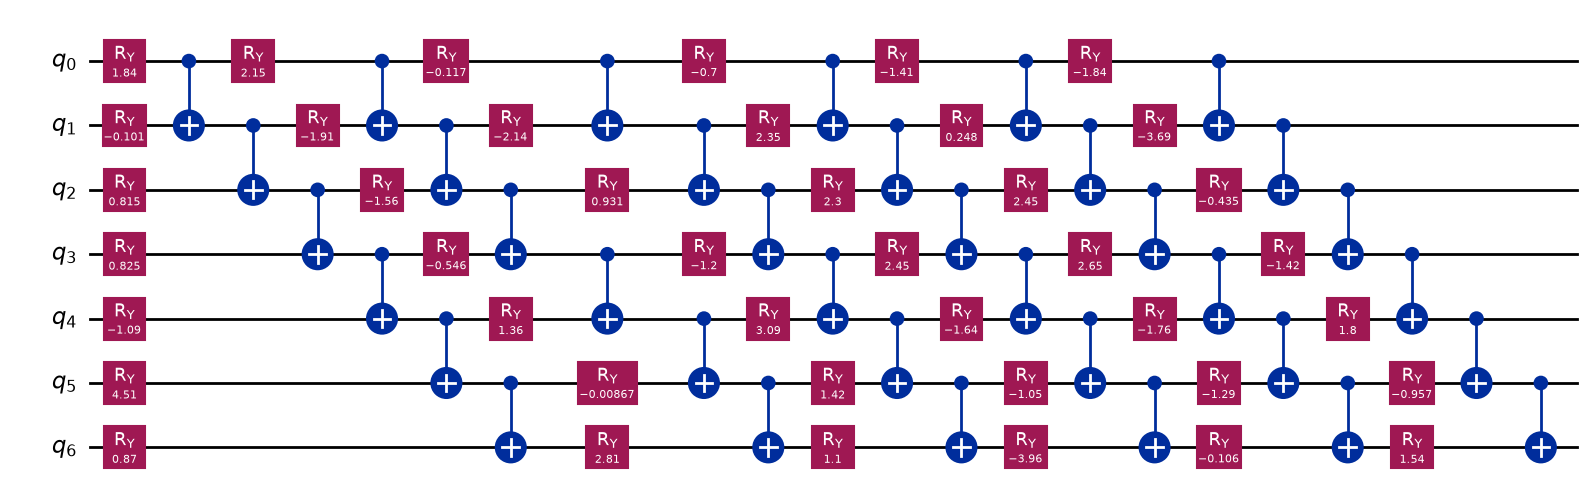


Dataset =  [[0, 0, 0, 0], [1, 0, 0, 0], [0, 1, 0, 0], [1, 1, 0, 0], [0, 0, 1, 0], [1, 0, 1, 0], [0, 1, 1, 0], [1, 1, 1, 0], [0, 0, 0, 1], [1, 0, 0, 1], [0, 1, 0, 1], [1, 1, 0, 1], [0, 0, 1, 1], [1, 0, 1, 1], [0, 1, 1, 1], [1, 1, 1, 1]]

Target state:


<IPython.core.display.Latex object>


Encoded state: 


<IPython.core.display.Latex object>


Fidelity between target and encoded state: 0.56575217


In [14]:
encoder = ApproximateAmplitudeEncoder()
A_parameters = encoder.generate_A(dataset, depth=6, epochs=500)


Number of feature qubits (n_data_q): 2
Number of value qubits (n_value_q): 1
Total number of qubits (total_qubits): 3
Total number of states (total_num_states): 8


/Users/sandalisingh/Documents/quantum-computing-lab/.venv/lib/python3.12/site-packages/qiskit/quantum_info/states/statevector.py:184: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.array(self.data, dtype=dtype, copy=copy)


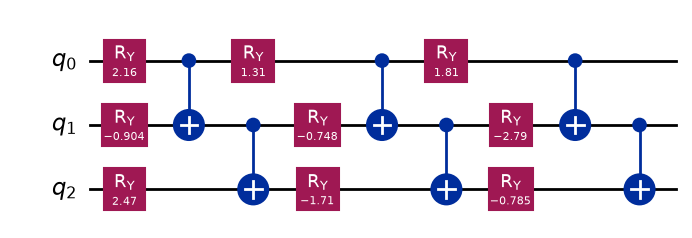


Query =  [1, 0, 0, 0]
Target state:


<IPython.core.display.Latex object>

Encoded state: 


<IPython.core.display.Latex object>

Fidelity between target and encoded state: 1.00000000


In [15]:
B_parameters = encoder.generate_B(query, depth=3, epochs=300)

### **<u>PART 2: UTILIZE GROVER SEARCH FOR IMAGE MATCHING</u>**

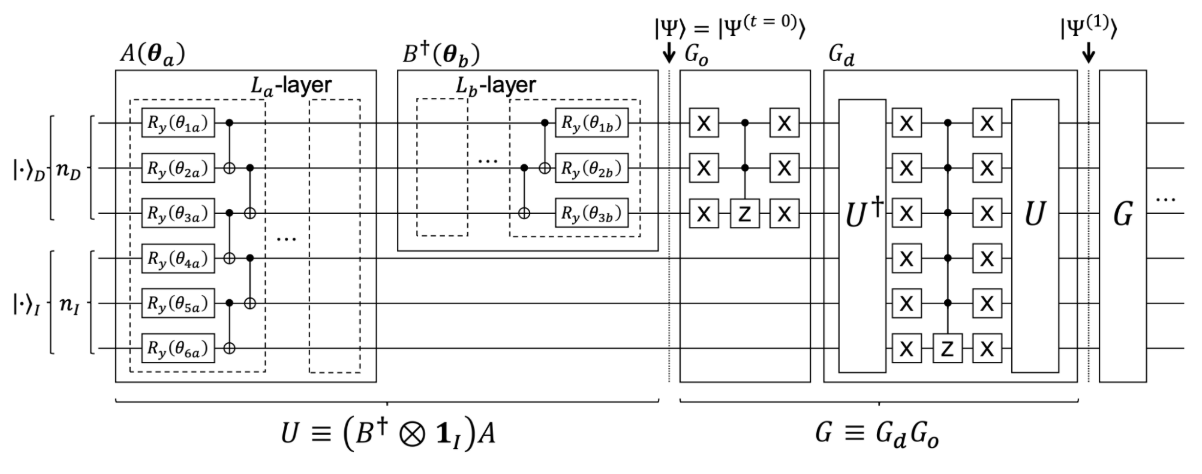

In [16]:
class GroverSearch:
  def pqc(self, parameters, depth, n_qubits):
    qc = QuantumCircuit(n_qubits)
    t = 0

    for _ in range(depth):
        # rotation layer
        for q in range(n_qubits):
            qc.ry(parameters[t], q)
            t += 1

        # entangling layer
        for q in range(n_qubits - 1):
            qc.cx(q, q + 1)

    return qc

  def build_U(self):
    # U = (B† ⊗ I_I) A
    # Qubit order: |data>|index>
    # A encodes the database, B† acts on data qubits only

    qc = QuantumCircuit(self.total_qubits)

    A = self.pqc(self.A_parameters, self.depth_A, self.total_qubits)
    B = self.pqc(self.B_parameters, self.depth_B, self.n_data_q)

    qc.compose(A, qubits=list(range(self.total_qubits)), inplace=True)
    qc.barrier()

    qc.compose(B.inverse(), qubits=self.data_q, inplace=True)
    qc.barrier()

    return qc

  def phase_flip_zero(self, qc, qubits):
    # Phase flip of |00...0> 
    # X gates convert |00...0> into |11...1>
    # H-MCX-H implements the multi-controlled Z operation to flip the phase of |11...1>

    if len(qubits) == 1:
        qc.x(qubits[0])
        qc.z(qubits[0])
        qc.x(qubits[0])

    else:
        qc.x(qubits)

        qc.h(qubits[-1])
        qc.mcx(qubits[:-1], qubits[-1])
        qc.h(qubits[-1])

        qc.x(qubits)

    return qc

  def oracle(self): # inversion-test oracle Go
    # Go phase-flips the all-zero data state after B†
    # This makes the phase depend on the query-data overlap

    qc = QuantumCircuit(self.total_qubits)

    self.phase_flip_zero(qc, self.data_q)
    qc.barrier()

    return qc

  def diffuser(self): # Gd = U† (phase flip of zero on all qubits) U
    # implements reflection about U|0>

    qc = QuantumCircuit(self.total_qubits)

    U = self.build_U()

    qc.compose(U.inverse(), qubits=list(range(self.total_qubits)), inplace=True)
    qc.barrier()

    self.phase_flip_zero(qc, list(range(self.total_qubits)))
    qc.barrier()

    qc.compose(U, qubits=list(range(self.total_qubits)), inplace=True)
    qc.barrier()

    return qc

  def visualize(self, qc, text):
    no_of_locators_on_chart = 10

    state = Statevector.from_instruction(qc)
    probs_dict = state.probabilities_dict(qargs=self.index_q)
    probs_dict = {int(k, 2): v for k, v in probs_dict.items()} # convert binary string keys to integers for better readability
    print(f"{text}: ", probs_dict)

    plot = plot_distribution(probs_dict, bar_labels=False)
    plot.axes[0].xaxis.set_major_locator(plt.MaxNLocator(no_of_locators_on_chart))

    display(plot)

  def run(self, dataset, query,
      A_parameters, B_parameters, depth_A=6, depth_B=3,
      num_of_iter=1, no_of_shots=2000
  ):
    # Dataset and query dimensions
    self.N_I = len(dataset)
    self.N_D = len(dataset[0])
    self.N_Q = len(query)

    # Number of index qubits
    self.n_index_q = math.ceil(math.log2(self.N_I))

    # Number of pixel-position qubits
    self.n_pixel_q = math.ceil(math.log2(self.N_D))

    # Use one consistent intensity range for the database and query.
    # For values 0..255, this gives 8 intensity qubits.
    max_value = max(int(np.max(dataset)), int(np.max(query)))
    self.n_value_q = max(1, math.ceil(math.log2(max_value + 1)))

    # The data register includes pixel-position AND intensity qubits.
    self.n_data_q = self.n_pixel_q + self.n_value_q

    # Total qubits = data register + image-index register
    self.total_qubits = self.n_index_q + self.n_data_q

    # Match the basis-state indexing used in prepare_neqr_dataset_target:
    # index bits are the least-significant bits.
    self.index_q = list(range(self.n_index_q))

    # B† acts on the entire data register, not just pixel-position qubits.
    self.data_q = list(range(self.n_index_q, self.total_qubits))

    # Keep the number of image-index states separate from the
    # dimension of the data register.
    self.padded_N_I = 2**self.n_index_q
    self.padded_N_P = 2**self.n_pixel_q

    print("Index qubits:", self.index_q)
    print("Data qubits:", self.data_q)
    print("Pixel-position qubits:", self.n_pixel_q)
    print("Intensity qubits:", self.n_value_q)
    print("Total qubits:", self.total_qubits)

    # pad the dataset and query to the power of 2

    padded_dataset = np.zeros((self.padded_N_I, self.padded_N_P))
    padded_dataset[:self.N_I, :self.N_D] = dataset
    dataset = padded_dataset

    padded_query = np.zeros(self.padded_N_P)
    padded_query[:self.N_Q] = query 
    query = padded_query

    # A and B parameters

    self.A_parameters = np.asarray(A_parameters)
    self.B_parameters = np.asarray(B_parameters)
    self.depth_A = depth_A
    self.depth_B = depth_B

    print("N = ", self.N_I)
    print("Index qubits = ", self.index_q)
    print("Data qubits = ", self.data_q)
    print("Total no of qubits = ", self.total_qubits)

    # num_of_iter = max(1, round(((math.pi / 4) * math.sqrt(self.N_I)) - 0.5))
    # print("\nGrover iterations: ", num_of_iter)

    index_qubits = QuantumRegister(self.n_index_q, name="index")
    data_qubits = QuantumRegister(self.n_data_q, name="data")
    value_qubits = QuantumRegister(self.n_value_q, name="value")
    qc = QuantumCircuit(index_qubits, data_qubits, value_qubits)
    
    qc = self.build_U()
    self.visualize(qc, "Encoded state U|Psi(0)>")

    for iteration in range(num_of_iter):
        print(f"\nGROVER ITERATION {iteration + 1}")

        print("\nOracle: ")
        oracle_circuit = self.oracle()
        qc.compose(oracle_circuit, qubits=list(range(self.total_qubits)), inplace=True)
        self.visualize(qc, "Oracle output")

        print("\nDiffuser: ")
        diffuser_circuit = self.diffuser()
        qc.compose(diffuser_circuit, qubits=list(range(self.total_qubits)), inplace=True)
        self.visualize(qc, "Diffuser output")

    print("\nFINAL MEASUREMENT")

    self.qc = qc.copy()

    classical_register = ClassicalRegister(self.n_index_q, name="index_result")
    self.qc.add_register(classical_register)

    self.qc.measure(self.index_q, classical_register)

    simulator = AerSimulator()
    compiled = transpile(self.qc, simulator)

    result = simulator.run(compiled, shots=no_of_shots).result()
    counts = result.get_counts()

    print(f"\nIndex measurement results for ({no_of_shots}) shots:")
    print(counts)

    self.qc = qc.copy()

  def draw_circuit(self):
    display(self.qc.draw("mpl"))

  def analysis(self):
    print("REGISTER ANALYSIS")

    print("Dataset size (N):", self.N_I)
    print("Index qubits:", len(self.index_q))
    print("Data qubits:", len(self.data_q))
    print("Total qubits:", self.qc.num_qubits)
    print("Classical bits:", self.qc.num_clbits)

    print("\nCIRCUIT ANALYSIS")

    print("Circuit width:", self.qc.width())
    print("Circuit size:", self.qc.size())
    print("Circuit depth/layers:", self.qc.depth())

    print("\nOPERATION COUNT")
    print(self.qc.count_ops())

  def visualize_probability(self, qc, text):
    state = Statevector.from_instruction(qc)
    probabilities = np.abs(state.data)**2

    # The index bits are the least-significant bits.
    # data = |00...0| therefore corresponds to state indices
    # 0, 1, ..., padded_N_I - 1.
    joint_probs = probabilities[:self.padded_N_I]

    success_probability = np.sum(joint_probs)

    print(f"\n{text}")
    print("P(index=k AND data=0):", joint_probs)
    print("Probability of data=0:", success_probability)

    if success_probability > 0:
        conditional_probs = joint_probs / success_probability
        print("P(index=k | data=0):", conditional_probs)
        print("Most likely index:", np.argmax(conditional_probs))

    plt.bar(range(self.padded_N_I), joint_probs)
    plt.xlabel("Database index")
    plt.ylabel("Joint probability")
    plt.title(text)
    plt.show()

In [17]:
GS = GroverSearch()

GS.run(dataset=dataset, query=query,
    A_parameters=A_parameters, B_parameters=B_parameters,
    depth_A=depth_A, depth_B=depth_B,
    num_of_iter=5
)

NameError: name 'depth_A' is not defined

In [ ]:
query_index

In [ ]:
GS.draw_circuit()

In [ ]:
GS.analysis()